# Diabetes Prevention Model: Random Forest
### CPSC 483 – Introduction to Machine Learning
**Phase 3: Model Selection, Development, and Evaluation**

**Author:** James Ubiadas

---

This notebook trains and evaluates a **Random Forest** classifier that predicts whether a patient has diabetes (`HasDiabetes` = 1) from eight health measurements. It uses the team's shared preprocessing in `preprocessing.py`, so the train/test split is identical to every other model in the project.

## 1. Why a Random Forest?

A **decision tree** asks a series of yes/no questions about the features (for example "Is Glucose > 127?") and ends at a leaf that predicts a class. A single tree is easy to read but tends to **overfit**: it memorizes the training data and does poorly on new patients.

A **Random Forest** is an *ensemble* of many decision trees. Two kinds of randomness make the trees different from each other:

1. **Bootstrap sampling (bagging):** each tree is trained on a random sample of the training rows, drawn with replacement.
2. **Random feature subsets:** at each split, a tree may only consider a random subset of the features (`max_features`).

To predict, every tree votes, and the forest reports the share of votes for each class. Averaging many different, noisy trees cancels out much of their individual error. This lowers variance without raising bias much.

**Why it fits this dataset:**
- It captures **non-linear relationships and interactions** (for example, high glucose matters more for older patients) without us having to design them.
- It **doesn't need feature scaling**, because trees split on thresholds, not distances.
- It's **robust to skewed features and outliers** like Insulin and Pedigree.
- It gives **feature importances**, which matter in a medical setting where we want to know *which* factors drive risk.
- It works well on small tabular datasets like this one (768 rows).

In [34]:
# Colab setup: get the team repo (preprocessing.py + Datasets/)
# Only runs in Colab; does nothing when run locally in VS Code.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("preprocessing.py"):
    !git clone https://github.com/cchung3231/CPSC-483-Project.git
    os.chdir("CPSC-483-Project")
print("Working folder:", os.getcwd())
print("Files here:", os.listdir("."))

Working folder: /content/CPSC-483-Project
Files here: ['requirements.txt', 'preprocessing.py', '.git', 'figures', 'Datasets', 'README.md', 'exploratory_analysis.ipynb', '.gitignore']


## 2. Imports

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report,
)

# Shared team preprocessing (same split for every model)
from preprocessing import load_data, split_data, make_preprocessor, RANDOM_STATE

FIG_DIR = Path("figures/random_forest")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 3. Load and split the data

`load_data()` replaces the medically impossible zeros (Glucose, BP, Skin, Insulin, BMI) with `NaN`. `split_data()` makes a stratified 80/20 split with `random_state=42`.

In [36]:
X, y = load_data()
X_train, X_test, y_train, y_test = split_data(X, y)

print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"Diabetes rate - train: {y_train.mean():.3f}, test: {y_test.mean():.3f}")

Train: (614, 8)  Test: (154, 8)
Diabetes rate - train: 0.349, test: 0.351


## 4. Build the pipeline

The pipeline has two steps:
1. **Median imputation**, which fills in the missing values. Scaling is turned off (`scale=False`) because trees don't need it.
2. **Random Forest classifier.**

Because the imputer sits *inside* the pipeline, its medians are learned from training data only. During cross-validation they're re-learned on each training fold, which prevents data leakage.

In [37]:
def make_rf_pipeline(**rf_params):
    return Pipeline([
        ("prep", make_preprocessor(scale=False)),
        ("rf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **rf_params)),
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

## 5. Baseline: default Random Forest

Before tuning, we measure a Random Forest with scikit-learn's default settings, using **5-fold stratified cross-validation on the training set only**. This gives a reference point, so we can tell whether tuning actually helped.

We also note the **majority-class baseline**: a "model" that always predicts *no diabetes* would already be about 65% accurate. Any useful model has to beat that clearly.

In [38]:
baseline = make_rf_pipeline()
base_cv = cross_validate(baseline, X_train, y_train, cv=cv, scoring=scoring)

base_summary = pd.DataFrame({
    m: [base_cv[f"test_{m}"].mean(), base_cv[f"test_{m}"].std()] for m in scoring
}, index=["mean", "std"]).T.round(3)

print(f"Majority-class accuracy: {1 - y_train.mean():.3f}")
base_summary

Majority-class accuracy: 0.651


,mean,std
accuracy,0.746,0.033
precision,0.659,0.061
recall,0.588,0.060
f1,0.617,0.038
roc_auc,0.803,0.010


## 6. Hyperparameter tuning with GridSearchCV

**Hyperparameters** are settings we choose before training, as opposed to things the model learns. The ones tuned here:

| Hyperparameter | What it controls | Why tune it |
|---|---|---|
| `n_estimators` | Number of trees | More trees give more stable votes, with diminishing returns |
| `max_depth` | How deep each tree can grow | Shallower trees overfit less |
| `min_samples_leaf` | Minimum patients in a leaf | Larger values smooth predictions and reduce overfitting |
| `max_features` | Features considered at each split | Lower values make the trees more different from each other |
| `class_weight` | Penalty for misclassifying each class | `"balanced"` makes errors on the smaller diabetes class count more |

`GridSearchCV` tries every combination with 5-fold cross-validation on the training set. It picks the best one by **ROC-AUC**, a metric that doesn't depend on a single decision threshold. **The test set is not touched here.**

In [23]:
param_grid = {
    "rf__n_estimators": [200, 500],
    "rf__max_depth": [None, 4, 6, 8],
    "rf__min_samples_leaf": [1, 3, 5],
    "rf__max_features": ["sqrt", 0.5],
    "rf__class_weight": [None, "balanced"],
}

grid = GridSearchCV(
    make_rf_pipeline(), param_grid, cv=cv, scoring=scoring,
    refit="roc_auc", n_jobs=-1, return_train_score=True,
)
grid.fit(X_train, y_train)

print("Best parameters:")
for k, v in grid.best_params_.items():
    print(f"  {k.replace('rf__', '')}: {v}")
print(f"\nBest CV ROC-AUC: {grid.best_score_:.3f}")

Best parameters:
  class_weight: balanced
  max_depth: 4
  max_features: sqrt
  min_samples_leaf: 1
  n_estimators: 200

Best CV ROC-AUC: 0.822


In [24]:
# Cross-validation scores of the best model, compared with the default baseline
best_idx = grid.best_index_
res = grid.cv_results_
tuned_summary = pd.Series(
    {m: res[f"mean_test_{m}"][best_idx] for m in scoring}, name="tuned (CV mean)"
).round(3)

comparison = pd.concat([base_summary["mean"].rename("default (CV mean)"), tuned_summary], axis=1)
comparison

,default (CV mean),tuned (CV mean)
accuracy,0.746,0.746
precision,0.659,0.616
recall,0.588,0.733
f1,0.617,0.667
roc_auc,0.803,0.822


In [25]:
# Overfitting check: training-fold score vs validation-fold score for the best model
print(f"Train ROC-AUC (CV): {res['mean_train_roc_auc'][best_idx]:.3f}")
print(f"Valid ROC-AUC (CV): {res['mean_test_roc_auc'][best_idx]:.3f}")

base_train = make_rf_pipeline().fit(X_train, y_train)
print(f"\nDefault RF training accuracy: {base_train.score(X_train, y_train):.3f}  (it memorizes the training set)")

Train ROC-AUC (CV): 0.915
Valid ROC-AUC (CV): 0.822

Default RF training accuracy: 1.000  (it memorizes the training set)


## 7. Final evaluation on the held-out test set

Now, and only once, we evaluate the tuned model on the 154 test patients it has never seen. We report five metrics:

- **Accuracy:** the share of all predictions that are correct. It can be misleading when the classes are imbalanced.
- **Precision:** of the patients flagged as diabetic, the share who really are. Low precision means many false alarms.
- **Recall (sensitivity):** of the patients who really have diabetes, the share we caught. For screening, this is often the most important metric, because a missed case can go untreated.
- **F1-score:** the harmonic mean of precision and recall. It balances the two.
- **ROC-AUC:** how well the predicted probabilities *rank* diabetic patients above non-diabetic ones, across every threshold. A value of 0.5 is random guessing and 1.0 is perfect.

In [26]:
best_rf = grid.best_estimator_
y_pred = best_rf.predict(X_test)
y_prob = best_rf.predict_proba(X_test)[:, 1]

test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
}, name="Test set").round(3)
test_metrics

,Test set
Accuracy,0.766
Precision,0.622
Recall,0.852
F1-score,0.719
ROC-AUC,0.875


In [27]:
print(classification_report(y_test, y_pred, target_names=["No diabetes", "Diabetes"], digits=3))

              precision    recall  f1-score   support

 No diabetes      0.900     0.720     0.800       100
    Diabetes      0.622     0.852     0.719        54

    accuracy                          0.766       154
   macro avg      0.761     0.786     0.759       154
weighted avg      0.802     0.766     0.772       154



### 7.1 Confusion matrix

The confusion matrix breaks the predictions into four counts:
- **True negatives** (top-left) and **true positives** (bottom-right) are correct predictions.
- **False positives** (top-right) are healthy patients flagged as diabetic.
- **False negatives** (bottom-left) are diabetic patients the model missed. In a medical setting, this is the most costly kind of error.

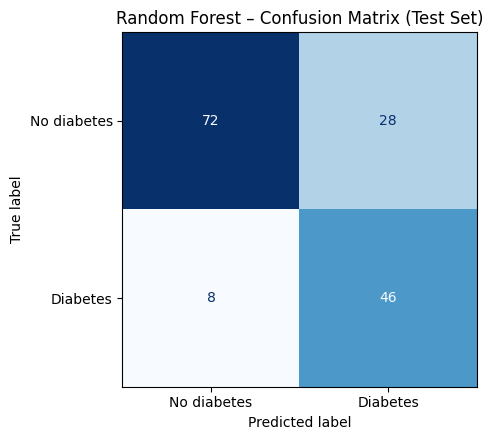

TN=72  FP=28  FN=8  TP=46


In [28]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No diabetes", "Diabetes"], cmap="Blues", ax=ax, colorbar=False
)
ax.set_title("Random Forest – Confusion Matrix (Test Set)")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix.png", dpi=150)
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

### 7.2 ROC curve

The ROC curve plots the **true positive rate** (recall) against the **false positive rate** as the decision threshold moves from 1 down to 0. The closer the curve hugs the top-left corner, the better. The dashed diagonal line is a random classifier.

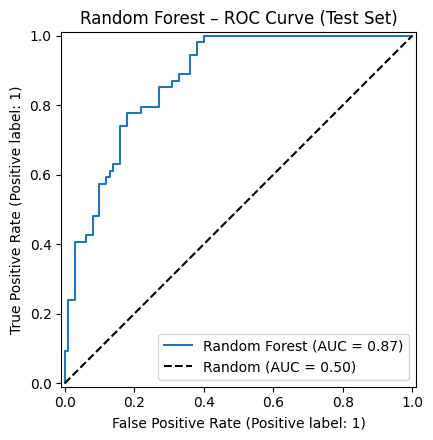

In [29]:
fig, ax = plt.subplots(figsize=(5, 4.5))
RocCurveDisplay.from_predictions(y_test, y_prob, name="Random Forest", ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.50)")
ax.set_title("Random Forest – ROC Curve (Test Set)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "roc_curve.png", dpi=150)
plt.show()

## 8. Feature importance

Which measurements does the forest rely on most? We look at two measures:

- **Impurity-based (MDI) importance:** how much each feature reduces Gini impurity across all splits, averaged over all trees. It's fast, but can favor features with many distinct values.
- **Permutation importance:** randomly shuffle one feature in the *test* set and measure how much ROC-AUC drops. A big drop means the model really depends on that feature. This method is more reliable.

In [30]:
feature_names = X_train.columns
mdi = pd.Series(best_rf.named_steps["rf"].feature_importances_, index=feature_names)

perm = permutation_importance(
    best_rf, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1
)
perm_imp = pd.Series(perm.importances_mean, index=feature_names)

importance = pd.DataFrame({"MDI importance": mdi, "Permutation (AUC drop)": perm_imp}).sort_values(
    "Permutation (AUC drop)", ascending=False
).round(3)
importance

,MDI importance,Permutation (AUC drop)
Glucose,0.344,0.131
BMI,0.203,0.044
Age,0.134,0.033
Pedigree,0.060,0.017
Insulin,0.113,0.013
Preg,0.062,0.008
Skin,0.044,0.002
BP,0.041,0.000


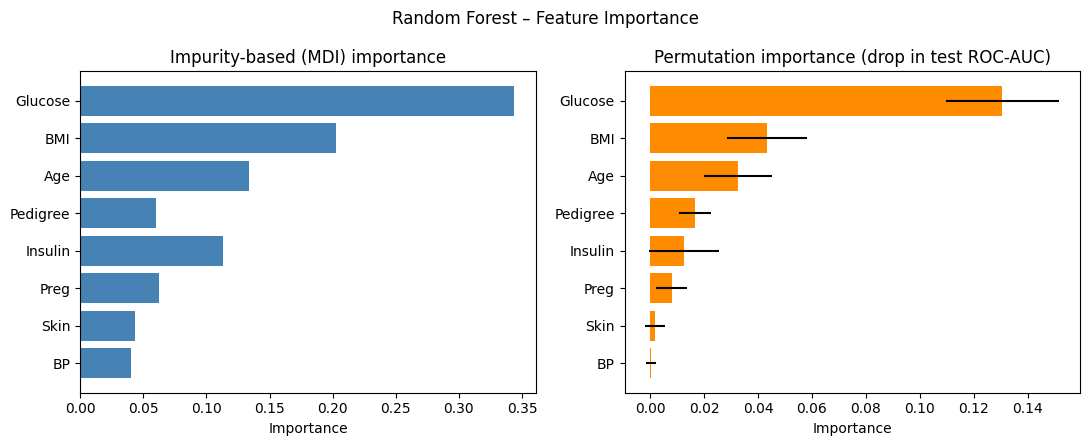

In [31]:
order = perm_imp.sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].barh(order, mdi[order], color="steelblue")
axes[0].set_title("Impurity-based (MDI) importance")
axes[1].barh(order, perm_imp[order], xerr=perm.importances_std[[list(feature_names).index(f) for f in order]],
             color="darkorange")
axes[1].set_title("Permutation importance (drop in test ROC-AUC)")
for ax in axes:
    ax.set_xlabel("Importance")
plt.suptitle("Random Forest – Feature Importance")
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_importance.png", dpi=150)
plt.show()

## 9. Choosing the decision threshold

By default, `predict()` labels a patient diabetic when the forest's probability is ≥ 0.5. For a **screening** tool, missing a diabetic patient (false negative) is usually worse than a false alarm, which only leads to a follow-up test. Lowering the threshold catches more true cases (higher recall) at the cost of more false alarms (lower precision).

The table below shows this trade-off. Note that picking a threshold *by looking at the test set* would be a form of leakage. In the report, present this as an analysis of the trade-off, not as a new tuned result.

In [32]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6]:
    p = (y_prob >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "F1": f1_score(y_test, p),
        "False negatives": int(((p == 0) & (y_test == 1)).sum()),
        "False positives": int(((p == 1) & (y_test == 0)).sum()),
    })
pd.DataFrame(rows).round(3)

,Threshold,Precision,Recall,F1,False negatives,False positives
0,0.3,0.509,1.000,0.675,0,52
1,0.4,0.576,0.907,0.705,5,36
2,0.5,0.622,0.852,0.719,8,28
3,0.6,0.680,0.630,0.654,20,16


## 10. Results summary

*(Fill in from the outputs above. See the walkthrough doc for how to interpret each number.)*

- **Performance:**
- **Strengths:**
- **Limitations:**
- **Most important features:**

In [33]:
# Save the key numbers so they can be pasted into the report / team comparison table
test_metrics.to_csv(FIG_DIR / "test_metrics.csv", header=["value"])
importance.to_csv(FIG_DIR / "feature_importance.csv")
print("Saved metrics and figures to", FIG_DIR)

Saved metrics and figures to figures/random_forest
